<a href="https://colab.research.google.com/github/gbkeku/safeshare-data-prep/blob/main/notebooks/01_SafeShare_Data_Prep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SafeShare, Notebook 1: Data Preparation and Data Insights

**Project.** SafeShare finds sensitive text in screenshots (names, email addresses, phone numbers, account and card numbers, US Social Security numbers, passwords, PINs and API keys) so a person can redact it before sharing. The detector is a BERT token classifier (`gravitee-io/bert-small-pii-detection`, fine-tuned in Notebook 3) that reads the text Tesseract OCR extracts from the image.

**This notebook** builds the data that model is trained and evaluated on, and documents it. It covers the three parts of the Data Prep criterion:

| Part | What is done | Sections |
|---|---|---|
| **Data cleanup** | Download a pinned dataset version, validate every annotation, remove duplicates, group related records, split without leakage, verify against the frozen run | 5, 6, 9, 10 |
| **Feature engineering** | Word-level BIO labels aligned to BERT sub-word tokens, overlapping 256-token windows; screenshots rendered with varied fonts, sizes, themes and layouts, then read by OCR | 6, 7, 11 |
| **Data insights** | Category, length, locale and domain distributions; OCR accuracy on its own, by category and by rendering condition | 8, 12, 13, 14 |

**Dataset.** [nvidia/Nemotron-PII](https://huggingface.co/datasets/nvidia/Nemotron-PII) (CC BY 4.0): 100,000 training and 100,000 test records of synthetic text across many domains and document formats, with character-level labels for more than 50 kinds of personal information. SafeShare uses seven categories built from eleven of those labels.

**How to run.** Colab, **CPU** runtime, top to bottom; about 2 hours, mostly OCR. Section 1 clones the code from this public repository ([gbkeku/safeshare-data-prep](https://github.com/gbkeku/safeshare-data-prep)); no files or tokens are needed, because the code, the dataset and the tokenizer are all public. By default (`UPLOAD = True`) the run uploads its data to your own Google Cloud bucket, named in the Colab Secrets (see Before you run); set `UPLOAD = False` for a run without Google Cloud. Either way, section 10 checks that this run rebuilds the frozen data run model v1 was trained on (`20261111T013302Z-e38b2785`).

**Earlier design.** The first version of this pipeline targeted a generative model (Qwen2.5-1.5B) and also wrote chat-style training examples. The project moved to a BERT token classifier; the configuration now uses BERT's own tokenizer and writes only the cleaned documents that the BERT model uses.

## Before you run

**Runtime:** Runtime > Change runtime type > **CPU**. A GPU is not needed. The run takes about 2 hours; keep the tab open.

**Code:** nothing to do. Section 1 clones the public repository [gbkeku/safeshare-data-prep](https://github.com/gbkeku/safeshare-data-prep), so no token is needed.

**Colab Secrets** (key icon on the left, **Secrets**; turn on **Notebook access** for each one you add):

| Secret | Value | Needed? |
|---|---|---|
| `HF_TOKEN` | a Hugging Face token (read access is enough) | Optional: the dataset and tokenizer are public; a token only avoids download rate limits |
| `GCP_PROJECT_ID` | your Google Cloud project ID | Yes, with the default `UPLOAD = True` |
| `GCS_BUCKET_NAME` | your bucket name | Yes, with the default `UPLOAD = True` |
| `GCS_DATASET_LOCATION` | `gs://<bucket>/safeshare/data` | Yes, with the default `UPLOAD = True` |

**With the default `UPLOAD = True`**, add the three Google Cloud secrets for your own project and bucket. With `UPLOAD = False` (section 3), no secrets are needed.

**Sign-ins:** section 3 asks you to sign in to Google Cloud once. With `UPLOAD = False`, section 15 asks you to connect **Google Drive** instead, to save a copy of the prepared data and the run record.


## 1. Get the code
Clones the public repository [gbkeku/safeshare-data-prep](https://github.com/gbkeku/safeshare-data-prep) (no token needed) and stops if a required file is missing.

The saved output below comes from the run that produced this notebook's results, which cloned the project's main repository (commit `9354f44`). That repository is private, so this cell now clones the public copy of the Data Prep code instead.

In [ ]:
import json, os, shutil, subprocess, sys
from pathlib import Path

REPO, DEST = "https://github.com/gbkeku/safeshare-data-prep.git", "/content/safeshare"
os.chdir("/content")                       # step out of DEST before deleting it
shutil.rmtree(DEST, ignore_errors=True)    # always a fresh copy
r = subprocess.run(["git", "clone", "--depth", "1", REPO, DEST], capture_output=True, text=True)
if r.returncode:
    raise SystemExit("Clone failed:\n" + r.stderr)
COMMIT = subprocess.check_output(["git", "-C", DEST, "rev-parse", "HEAD"], text=True).strip()

ROOT = Path(DEST)
missing = [p for p in ("src/data_prep.py", "src/prepare_images.py", "src/gcs_io.py", "src/data_insights.py",
                       "src/bert_ner.py", "src/plots.py", "configs/data_prep.json", "configs/train.json") if not (ROOT / p).exists()]
if missing:
    raise SystemExit(f"The code is missing: {missing}")
os.chdir(DEST)
sys.path.insert(0, DEST)                   # `from src.xxx import ...` needs the project root on the path
print("Ready:", DEST, "| code:", COMMIT)

Ready: /content/safeshare | code: 9354f44b751cbe3fafee732bf3a21e4459b5de98


## 2. Install dependencies
Pinned versions of the Hugging Face libraries, plus Tesseract OCR and the DejaVu fonts used to render screenshots. If Colab asks for a restart, restart and rerun from section 1.

In [ ]:
import shutil, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets==4.4.1", "transformers==4.57.1",
                "huggingface-hub==0.36.0", "fsspec==2025.10.0", "google-cloud-storage", "fonttools>=4.50",
                "rapidfuzz>=3.0", "Pillow>=10.1,<14", "matplotlib", "pyarrow"], check=True)
subprocess.run(["apt-get", "update", "-q"])      # Colab may have Tesseract already but not the DejaVu fonts, so always install both
subprocess.run(["apt-get", "install", "-y", "-q", "tesseract-ocr", "tesseract-ocr-eng", "fonts-dejavu-core"], check=True)
print(subprocess.check_output(["tesseract", "--version"], text=True, stderr=subprocess.STDOUT).splitlines()[0])

tesseract 5.3.4


## 3. Settings
`UPLOAD = True` (the default) uploads the run's raw data, prepared data and screenshots to the bucket named in your Colab Secrets in section 15, and publishes a receipt for the run. Every file is written create-only, so a new run never replaces an earlier one. Set it to `False` for a local run: nothing is uploaded and no secrets are needed.

The data run model v1 was trained on (`20261111T013302Z-e38b2785`) stays frozen in the project's own bucket; publishing a new run there would mean retraining and re-evaluating every model.

In [ ]:
UPLOAD = True

def secret(name, required=True):
    try:
        from google.colab import userdata
        return userdata.get(name).strip()
    except Exception:
        if required:
            raise SystemExit(f"Add the Colab Secret {name} and turn on Notebook access.")

HF_TOKEN = secret("HF_TOKEN", required=False) or False     # optional: the dataset and models are public
if UPLOAD:
    from google.colab import auth
    from google.cloud import storage
    PROJECT, BUCKET = secret("GCP_PROJECT_ID"), secret("GCS_BUCKET_NAME")
    DATA_URI = secret("GCS_DATASET_LOCATION").rstrip("/")
    auth.authenticate_user()
    gcs = storage.Client(project=PROJECT)
    if gcs.lookup_bucket(BUCKET) is None:
        raise SystemExit(f"Bucket {BUCKET} not found or no access.")
    print("Bucket access OK")
else:
    print("Local run: nothing will be uploaded.")

Bucket access OK


## 4. Configuration
All settings come from `configs/data_prep.json`: the dataset and tokenizer at pinned revisions, the random seed, the validation share (20%), the test size (10,000), the BERT window length (256 tokens), the label mapping and the screenshot sample sizes. Each run gets a unique ID, and its outputs go to `artifacts/<kind>/<run ID>/`.

In [ ]:
import json
from datetime import datetime, timezone
from uuid import uuid4
from src.data_prep import load_config

config = load_config(ROOT / "configs/data_prep.json")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
RAW, PREPARED, IMAGES = (ROOT / "artifacts" / kind / RUN_ID for kind in ("raw", "prepared", "images"))
print("Run:", RUN_ID, "| seed:", config["seed"])

Run: 20261118T004701Z-98d5874e | seed: 42


## 5. Download the dataset and keep an unchanged copy
Loads the official train and test partitions at a pinned revision, so the same code always gets the same data. An untouched copy is saved as Parquet with an attribution file and a manifest of SHA-256 hashes, so every later step can be traced back to the exact source.

In [ ]:
from src.data_prep import load_source
from src.gcs_io import save_raw_snapshot

source = load_source(config, hf_token=HF_TOKEN)
print("Source rows:", {name: len(split) for name, split in source.items()})
save_raw_snapshot(source, config, RAW)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/156M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/151M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Source rows: {'train': 100000, 'test': 100000}


Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

{'schema_version': 'safeshare-raw-v1',
 'kind': 'raw_source_snapshot',
 'dataset_id': 'nvidia/Nemotron-PII',
 'dataset_revision': 'b70ffaf5ff39e079776134c5bf4381f00a9fd1ed',
 'source_counts': {'train': 100000, 'test': 100000},
 'files': {'ATTRIBUTION.txt': {'sha256': 'd4b70969322a168c6ef164a10f7ff9624d8f5b50864c4c0b5c94111303dfb502',
   'size_bytes': 407},
  'test.parquet': {'sha256': 'd3853b114db56c53ac1e2073f6776cca10344c6ad31e7d1717b56da4135cb6a9',
   'size_bytes': 146495135},
  'train.parquet': {'sha256': 'ed2ff9067e2c16d3d429b336114e66e82740998549ec0455344d9d6bdffee991',
   'size_bytes': 152048489}},
 'release_id': 'safeshare-raw-5ad9414a385e5f73'}

## 6. Clean, group, split, and build the BERT features
**Cleaning.** Each record is checked: text present and not oversized, every label inside the text, and, for the seven SafeShare categories, the labeled text must match the document exactly. A record that fails any check is removed whole, never repaired, because a wrong label teaches the model the wrong thing. Exact duplicates, and duplicates whose labels disagree, are removed. Adjacent first and last names are merged into one PERSON span.

**Grouping and splitting.** Records are grouped when they share a source ID (Nemotron has a US and an international version of each record), the same normalized text, or the same template with the personal details masked. Whole groups are assigned to a split, so near-copies never sit on both sides. Training records that share a group with any test record are removed. All eligible training records are split 80/20 into train and validation; 10,000 official test records form the test split. The code stops with an error if any document, source, group or text appears in two splits.

**Features.** Each document is split into words, and each label is widened to whole words. The BERT tokenizer then counts sub-word tokens per document and the overlapping 256-token windows `src/train.py` trains on ("examples" below). The charts show entity counts, document lengths, BERT tokens per document, and split sizes.

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

{
  "train": {
    "documents": 79598,
    "examples": 122453,
    "groups": 39927,
    "source_split": "train"
  },
  "validation": {
    "documents": 19899,
    "examples": 30718,
    "groups": 9981,
    "source_split": "train"
  },
  "test": {
    "documents": 10000,
    "examples": 15080,
    "groups": 5012,
    "source_split": "test"
  }
}


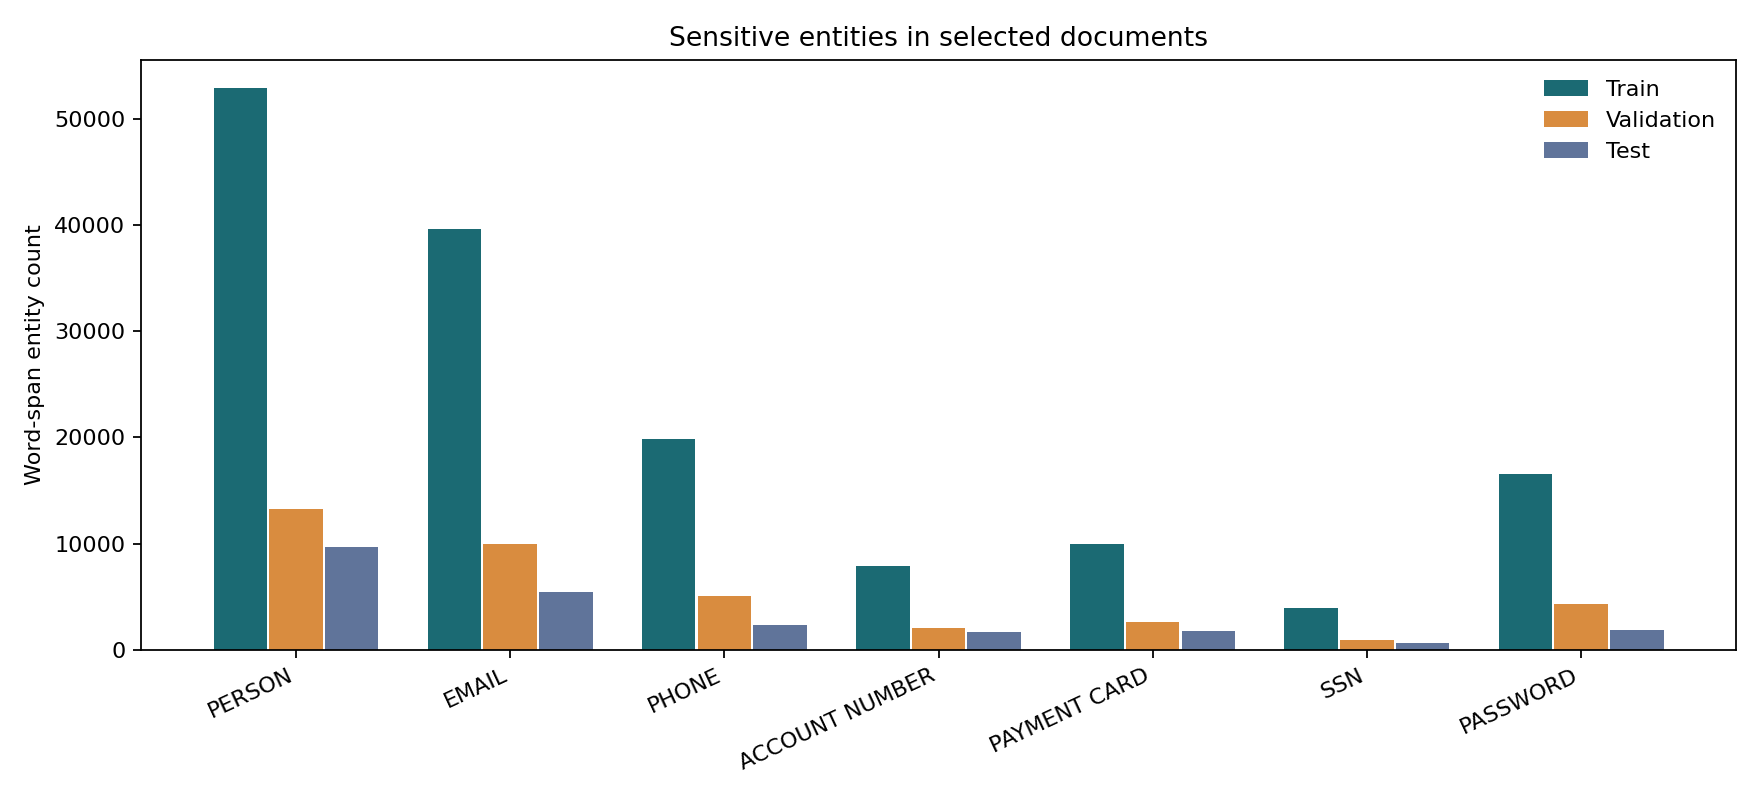

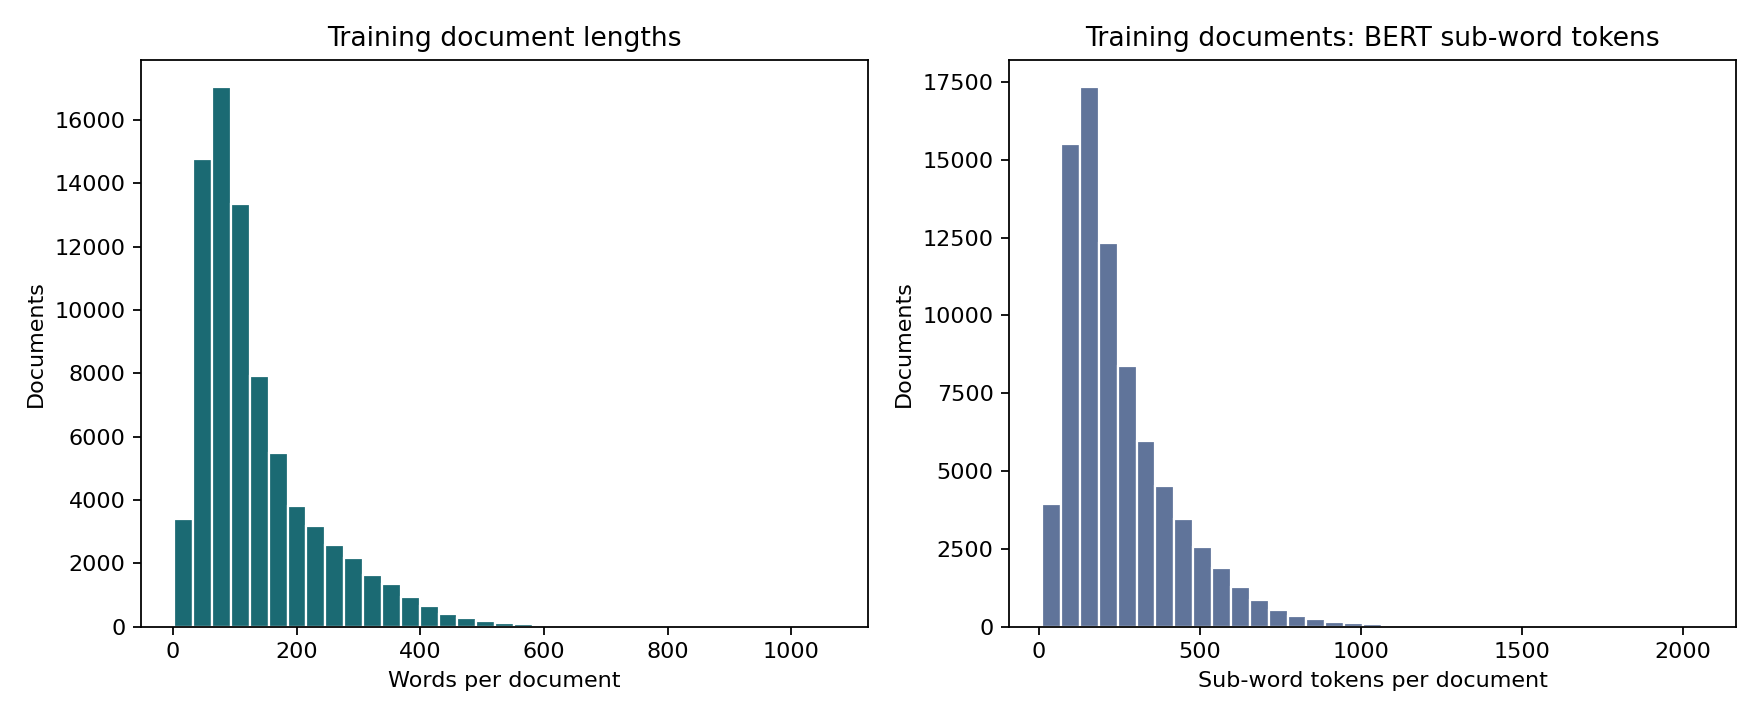

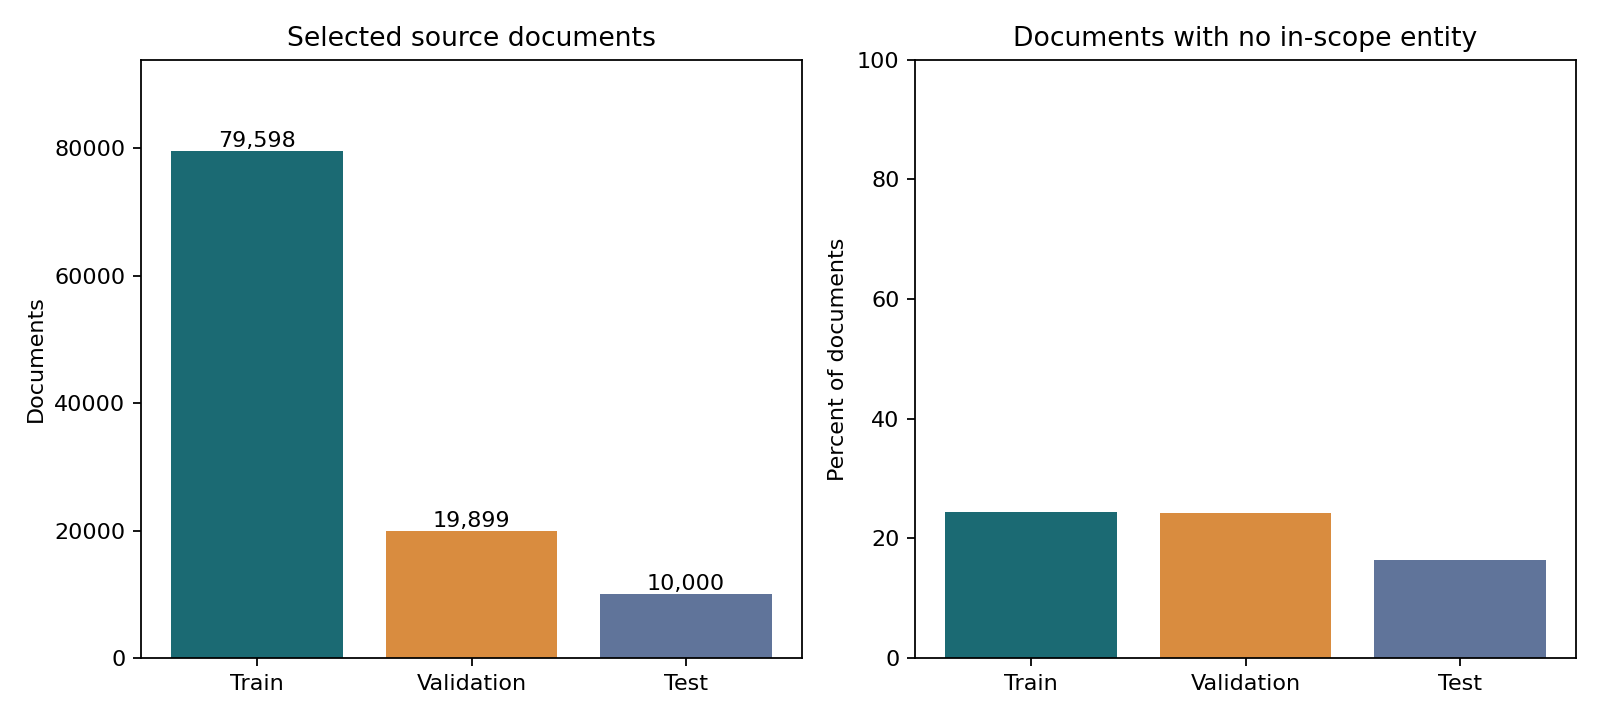

In [ ]:
from transformers import AutoTokenizer
from IPython.display import Image, display
from src.data_prep import prepare_data

tokenizer = AutoTokenizer.from_pretrained(config["model_id"], revision=config["model_revision"], token=HF_TOKEN)
text = prepare_data(source, tokenizer, config, PREPARED)       # verifies its own output
print(json.dumps(text["split_summary"], indent=2))
for figure in sorted((PREPARED / "figures").glob("*.png")):    # charts for the report
    display(Image(str(figure)))

## 7. Screenshot sample: render and run OCR
SafeShare reads screenshots, so a sample of documents is rendered as images. The sample is balanced: every category has at least `min_entities_per_label` examples where the data allows, and about 15% of documents contain no sensitive text, so the model also sees screenshots it should leave alone.

Rendered screenshots look cleaner than real ones, so the rendering is randomized per document: font (sans or serif), font size (14 to 28 px), light or dark theme, layout (chat, dialog, form, log), scaling and slight blur. The test split also holds out one font (monospace) and one layout (ticket) that never appear in training, as a check on unseen styles. Each page is saved as PNG and as JPEG (paired copies, not independent samples), read by Tesseract, and stored with gold boxes for every sensitive word. The first cell only counts the planned sample, so a shortfall shows up before the long rendering run.

In [ ]:
from src.gcs_io import sha256_file
from src.prepare_images import preview_selection, prepare_images

manifest_hash = sha256_file(PREPARED / "manifest.json")     # ties the images to exactly this text release
plan = preview_selection(PREPARED, config["image"], manifest_hash)
print(json.dumps(plan, indent=2))
if any(v["shortfalls"] for v in plan.values()):
    raise RuntimeError("Category shortfall: raise the split sizes in configs/data_prep.json before rendering.")

{
  "train": {
    "documents": 1500,
    "negative_documents": 225,
    "entities": {
      "PERSON": 1151,
      "EMAIL": 979,
      "PHONE": 502,
      "ACCOUNT_NUMBER": 268,
      "PAYMENT_CARD": 320,
      "SSN": 169,
      "PASSWORD": 422
    },
    "shortfalls": {}
  },
  "validation": {
    "documents": 200,
    "negative_documents": 30,
    "entities": {
      "PERSON": 222,
      "EMAIL": 154,
      "PHONE": 127,
      "ACCOUNT_NUMBER": 107,
      "PAYMENT_CARD": 117,
      "SSN": 107,
      "PASSWORD": 119
    },
    "shortfalls": {}
  },
  "test": {
    "documents": 300,
    "negative_documents": 45,
    "entities": {
      "PERSON": 380,
      "EMAIL": 226,
      "PHONE": 143,
      "ACCOUNT_NUMBER": 133,
      "PAYMENT_CARD": 127,
      "SSN": 100,
      "PASSWORD": 131
    },
    "shortfalls": {}
  }
}


In [ ]:
images = prepare_images(PREPARED, IMAGES, config["image"], expected_text_manifest_sha256=manifest_hash)
print(json.dumps(images["summary"]["overall"], indent=2))
print(images["summary"]["warnings"])

train: 100/1500 documents, 308s
train: 200/1500 documents, 593s
train: 300/1500 documents, 874s
train: 400/1500 documents, 1159s
train: 500/1500 documents, 1421s
train: 600/1500 documents, 1735s
train: 700/1500 documents, 2047s
train: 800/1500 documents, 2352s
train: 900/1500 documents, 2645s
train: 1000/1500 documents, 2935s
train: 1100/1500 documents, 3196s
train: 1200/1500 documents, 3462s
train: 1300/1500 documents, 3748s
train: 1400/1500 documents, 4022s
train: 1500/1500 documents, 4437s
validation: 100/200 documents, 4705s
validation: 200/200 documents, 5064s
test: 100/300 documents, 5336s
test: 200/300 documents, 5616s
test: 300/300 documents, 5967s
{
  "images": 5076,
  "ocr_failures": 0,
  "ocr_empty": 2,
  "cer": 0.03081506203050148,
  "wer": 0.03589029319347304,
  "word_recall": 0.9670236480745329,
  "sensitive_entities": 12010,
  "sensitive_located_rate": 0.9995836802664446,
  "sensitive_read_exact_rate": 0.920233139050791,
  "by_label": {
    "PERSON": {
      "entities": 

## 8. OCR on its own
Tesseract is evaluated before any detector is involved, because a word OCR misses can never be redacted: OCR quality caps the whole system.

- **CER / WER:** character and word error rates against the rendered text.
- **Word recall:** the share of words Tesseract found.
- **Located:** every word piece of a sensitive span has an OCR word on it, so it can be boxed.
- **Read exact:** OCR also spelled it correctly, so the model sees the right text.

The charts below show OCR confidence for sensitive and ordinary words, error by font and size, and sample pages (red boxes: labeled sensitive text; blue boxes: words OCR found).

Tesseract (PNG + JPEG): CER 0.031 | WER 0.036 | word recall 0.967 | sensitive text read exactly 0.920 (located 1.000)


,split,label,entities,located,read_exact,read_exact_rate
0,train,PERSON,1151,1151,1138,0.989
1,train,EMAIL,979,979,904,0.923
2,train,PHONE,502,502,493,0.982
3,train,ACCOUNT_NUMBER,268,268,259,0.966
4,train,PAYMENT_CARD,320,320,319,0.997
5,train,SSN,169,169,157,0.929
6,train,PASSWORD,422,422,289,0.685
7,validation,PERSON,222,222,217,0.977
8,validation,EMAIL,154,154,140,0.909
9,validation,PHONE,127,125,113,0.890


ocr_confidence.png


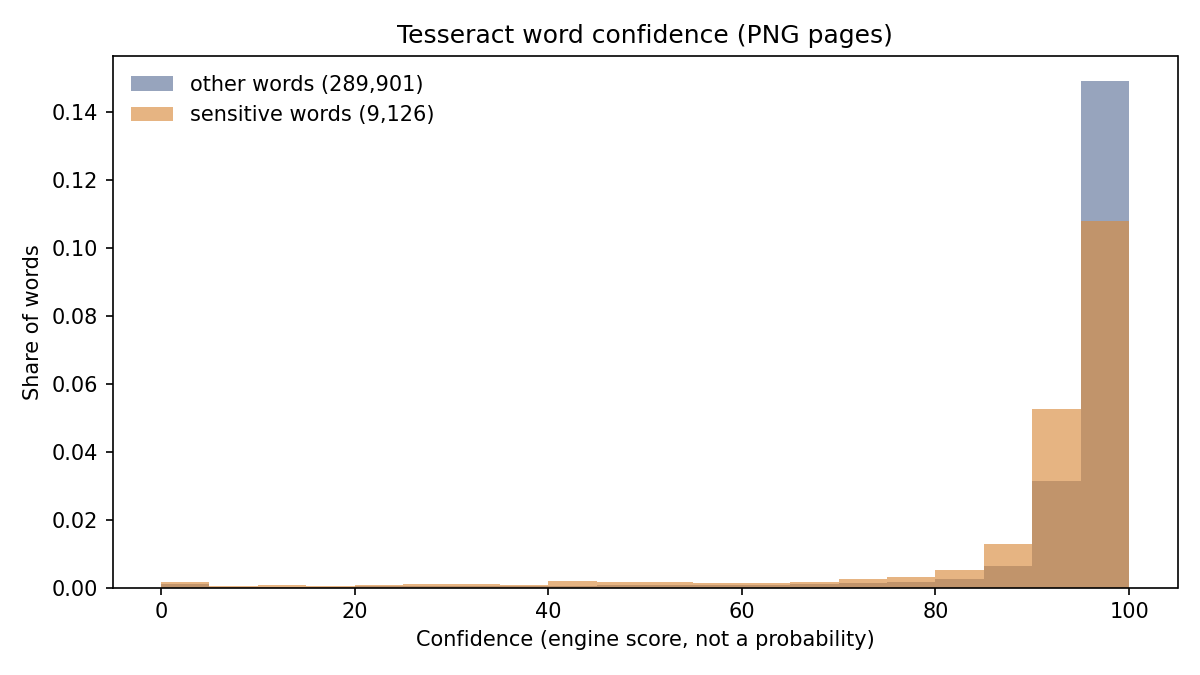

ocr_error_by_font_size.png


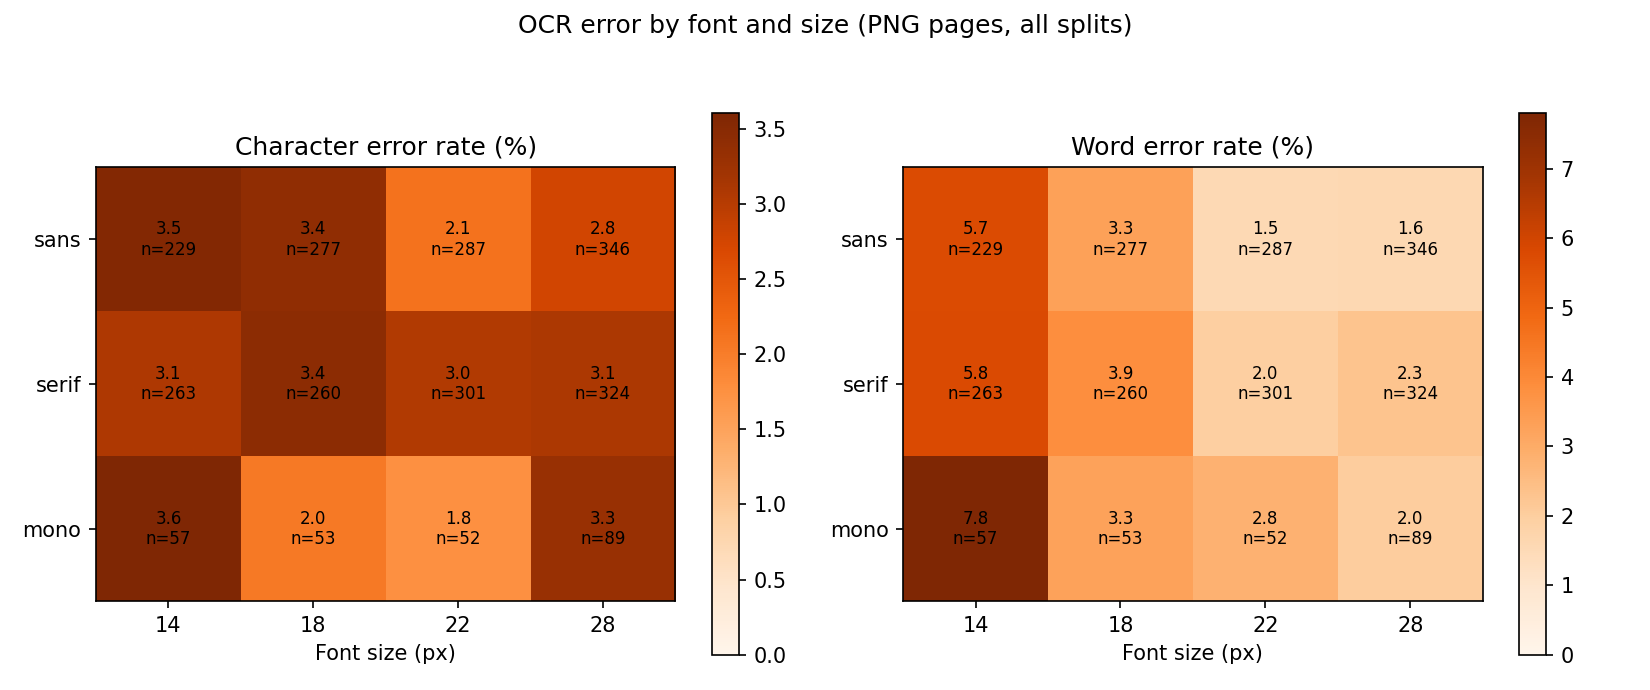

sample_0_train_sans_dialog_dark.png


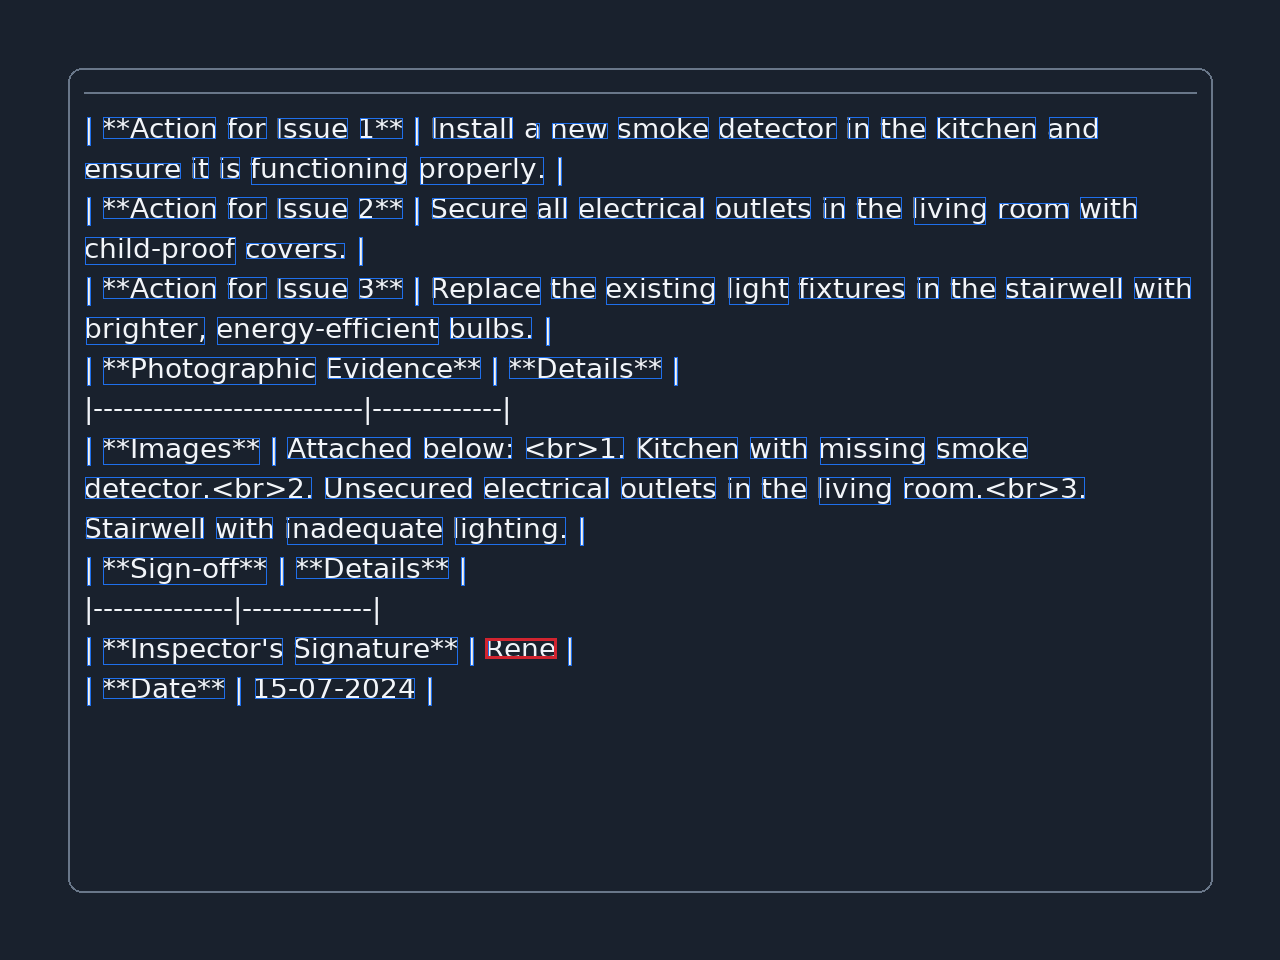

sample_1_train_sans_chat_dark.png


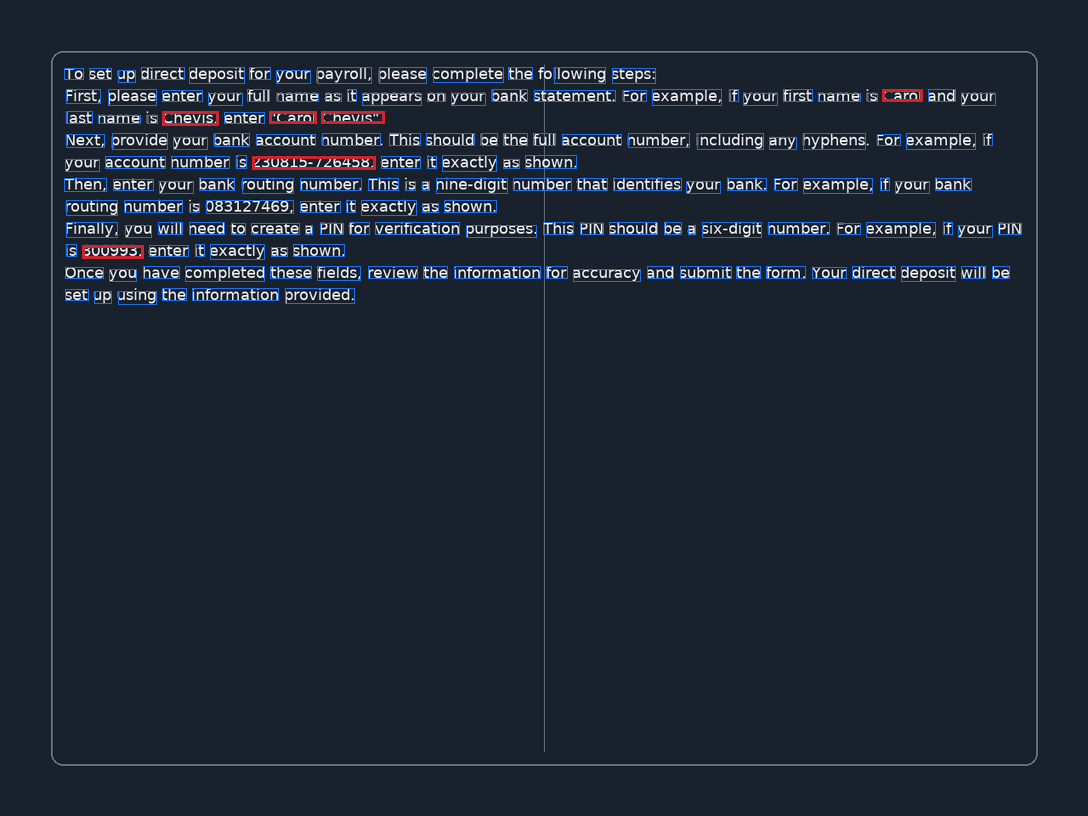

sample_2_validation_serif_dialog_dark.png


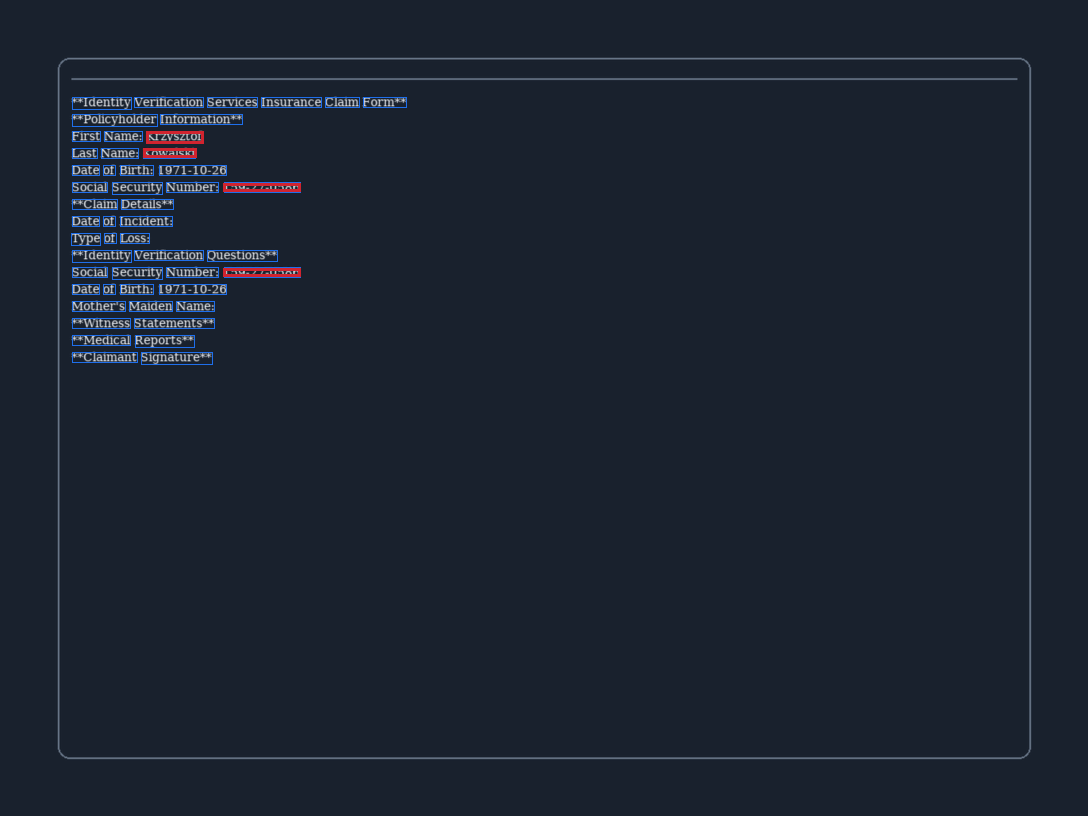

sample_3_validation_sans_dialog_dark.png


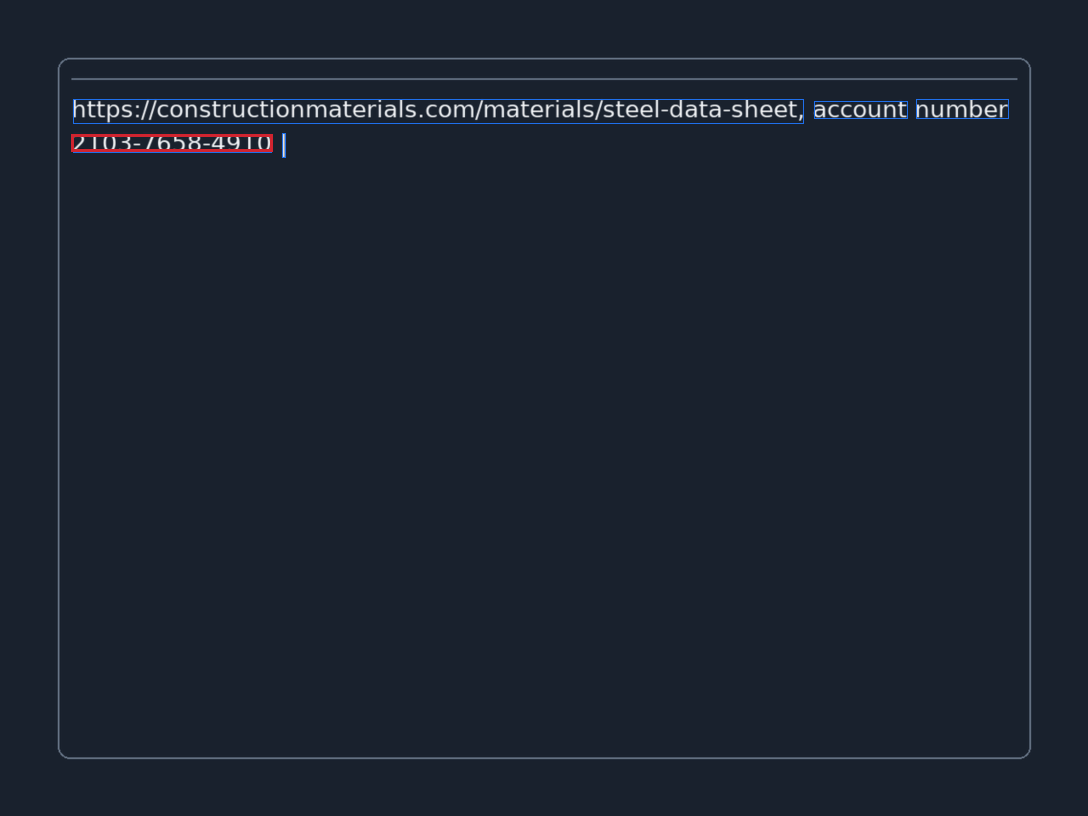

sample_4_test_mono_ticket_dark.png


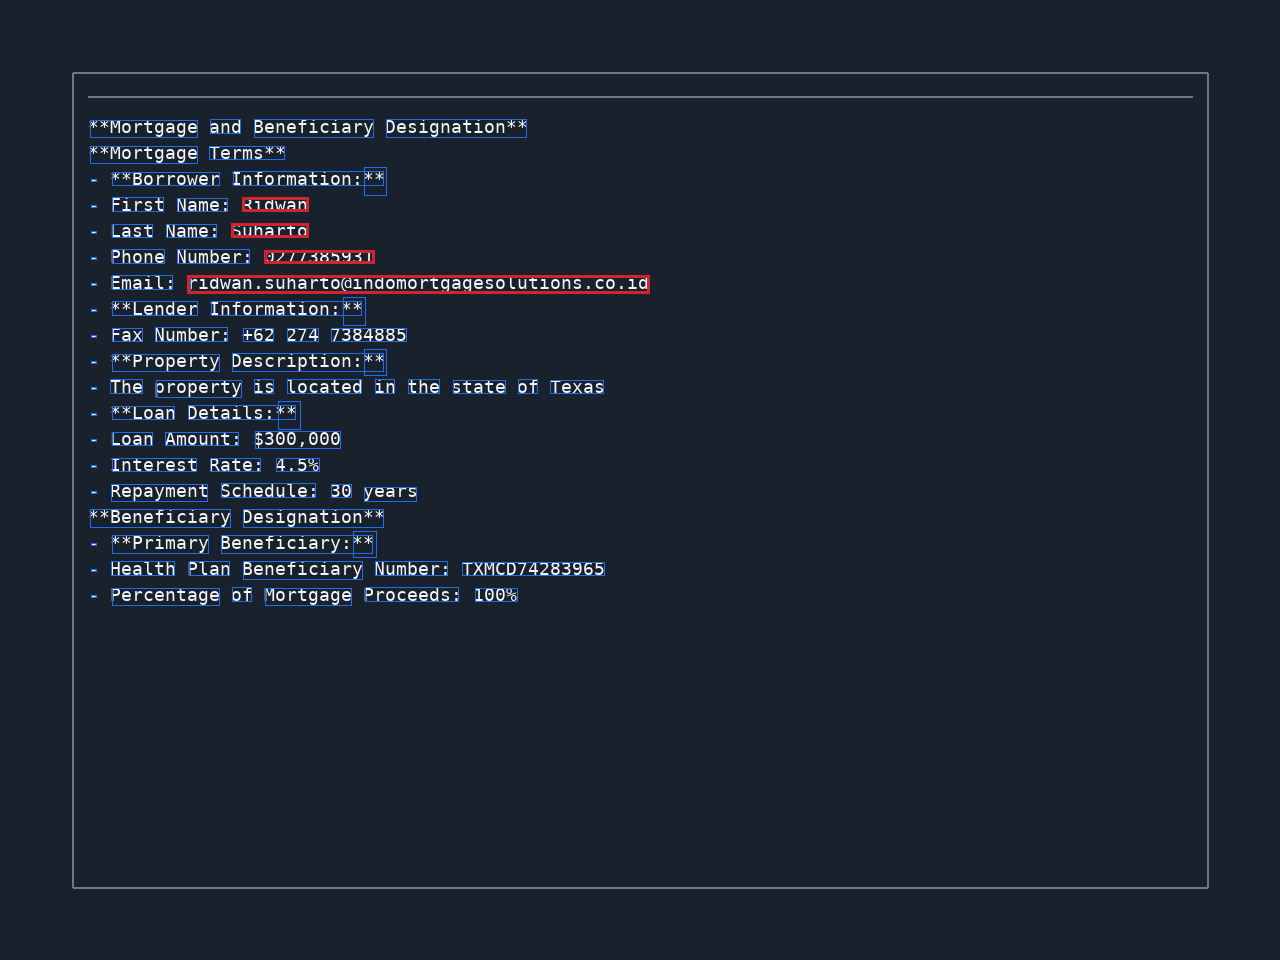

sample_5_test_sans_dialog_light.png


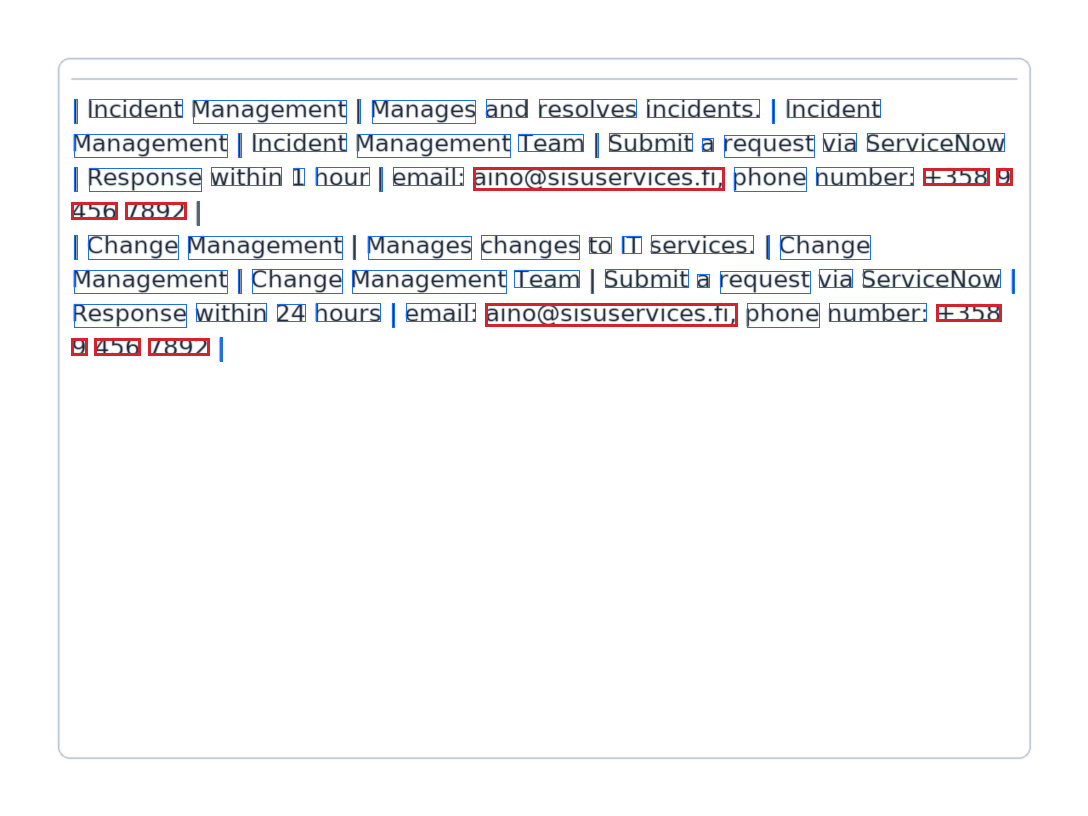

In [ ]:
import pandas as pd
from IPython.display import Image, display

summary = images["summary"]
o = summary["overall"]
print(f"Tesseract (PNG + JPEG): CER {o['cer']:.3f} | WER {o['wer']:.3f} | word recall {o['word_recall']:.3f} | "
      f"sensitive text read exactly {o['sensitive_read_exact_rate']:.3f} (located {o['sensitive_located_rate']:.3f})")
table = pd.DataFrame([{"split": s, "label": label, **v} for s in summary["splits"]
                      for label, v in summary["splits"][s]["png"]["by_label"].items()])
table["read_exact_rate"] = (table["read_exact"] / table["entities"]).round(3)
display(table)                                                  # PNG pages, per split and category
for figure in sorted((IMAGES / "figures").glob("*.png")):       # confidence, error by font and size, sample pages
    print(figure.name)
    display(Image(str(figure)))

## 9. Label mapping report
Eleven source labels are mapped to the seven SafeShare categories (for example `first_name` and `last_name` to PERSON, `password`, `pin` and `api_key` to PASSWORD, `credit_debit_card` and `cvv` to PAYMENT_CARD). Every other source label is out of scope: it is counted here, never relabeled, and its text stays in the documents as ordinary words, so the model learns to leave it alone. Out-of-scope types such as street addresses and dates of birth are listed as limits of the app.

In [ ]:
import pandas as pd
src = text["audit"]["source_splits"]
rows = [{"split": s, "source_label": label, "mapped_to": config["label_map"].get(label, "(not mapped)"), "spans": n}
        for s in ("train", "test") for label, n in src[s]["source_label_counts"].items()]
mapping = (pd.DataFrame(rows).pivot_table(index=["source_label", "mapped_to"], columns="split", values="spans",
           fill_value=0).reset_index().sort_values(["mapped_to", "train"], ascending=[True, False]))
mapping[["train", "test"]] = mapping[["train", "test"]].astype(int)
display(mapping)
label_mapping = json.loads(mapping.to_json(orient="records"))

split,source_label,mapped_to,test,train
8,company_name,(not mapped),54616,84917
15,date,(not mapped),73620,76743
52,url,(not mapped),37729,44584
36,occupation,(not mapped),36678,30840
10,country,(not mapped),23361,27652
50,time,(not mapped),24417,20926
7,city,(not mapped),18263,19177
46,state,(not mapped),18175,18749
13,customer_id,(not mapped),20464,17180
47,street_address,(not mapped),16826,16753


## 10. Cleanup evidence and reproducibility
**Funnel.** Every row from the source to the final splits, with how many were removed at each step and why.

**Split overlap.** Counts of shared IDs, sources, groups and texts between each pair of splits. All must be zero; the split code refuses to finish otherwise.

**Reproducibility.** The test documents and screenshot records are hashed and compared with the frozen data run model v1 was trained on (`data/receipt_20261111T013302Z-e38b2785.json`). A match means this notebook rebuilds exactly the data the reported results come from. (The frozen run also hashed its chat-style example file from the earlier design; this run does not write that file, so it is not compared.)

,step,rows,note
0,Source rows (official train + test),200000,None
1,Rejected: invalid records,-759,"out-of-bounds or mismatched spans, empty text,..."
2,Removed: training rows in the same group as a ...,-8,prevents near-copies of test records in training
3,Removed: exact duplicates,-1,None
4,"Removed: conflicting duplicates (same text, di...",0,None
5,Official test rows not sampled,-89735,"test fixed at 10,000 documents"
6,Final: train + validation + test,109497,None


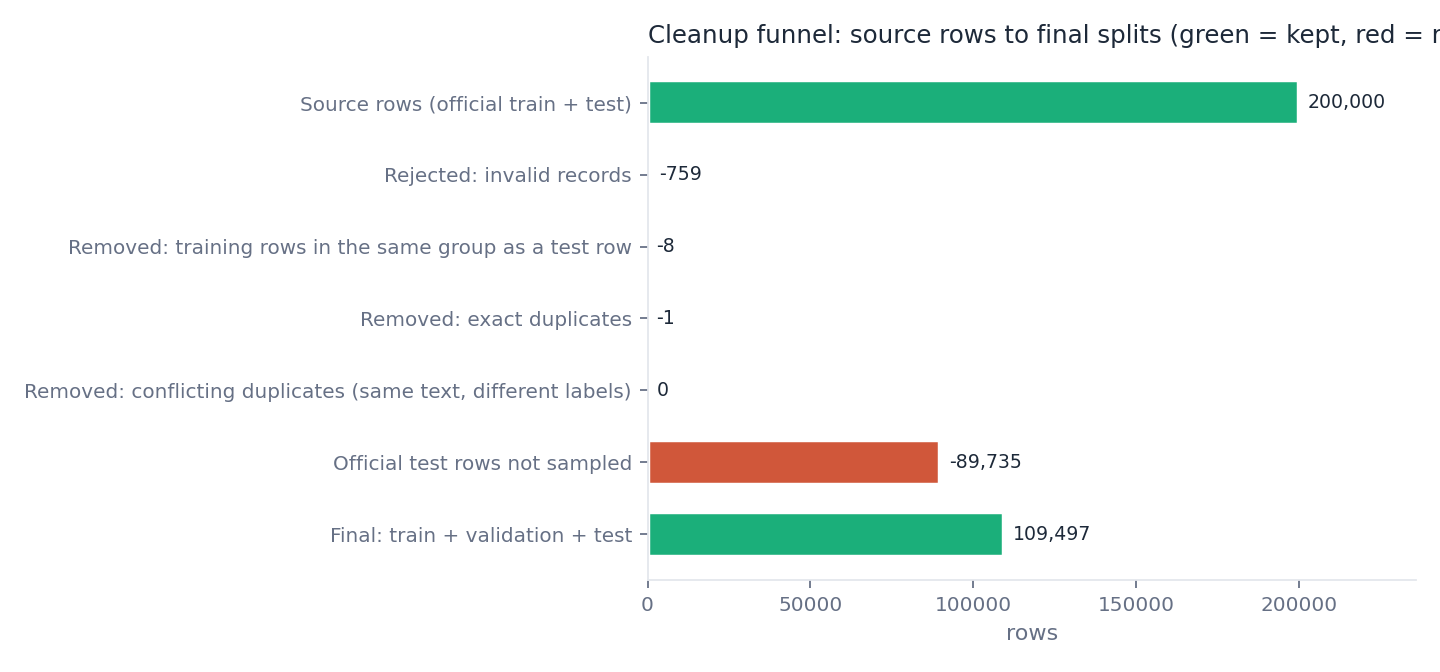

Why records were rejected:


,reason,rows
0,in_scope_surface_mismatch,759


,split,documents,groups,documents_without_sensitive_text,share_without_sensitive_text
0,train,79598,39927,19447,0.2443
1,validation,19899,9981,4827,0.2426
2,test,10000,5012,1645,0.1645


Overlap between splits (must be all zeros):


,key,train:validation,train:test,validation:test
0,id,0,0,0
1,source_uid,0,0,0
2,group_id,0,0,0
3,exact_text_sha256,0,0,0
4,normalized_text_sha256,0,0,0
5,template_sha256,0,0,0


,file,this_run,frozen_run,same
0,text_documents,24104d47b1c1d544,24104d47b1c1d544,True
1,image_records,ec47b71ae8059c7c,ec47b71ae8059c7c,True


This run rebuilt the frozen test split exactly.


In [ ]:
import pandas as pd
from IPython.display import Image, display
from src import data_insights as di
from src.gcs_io import sha256_file

REPORT = ROOT / "artifacts" / "report" / RUN_ID
REPORT.mkdir(parents=True, exist_ok=True)
FUNNEL, REJECTED, SPLITS, LEAKAGE = di.cleanup_funnel(text["audit"])
display(FUNNEL)
display(Image(di.funnel_chart(FUNNEL, REPORT / "cleanup_funnel.png")))
print("Why records were rejected:"); display(REJECTED)
display(SPLITS)
print("Overlap between splits (must be all zeros):"); display(LEAKAGE)
for t, n in ((FUNNEL, "cleanup_funnel"), (REJECTED, "rejection_reasons"), (SPLITS, "splits"), (LEAKAGE, "split_overlap")):
    t.to_csv(REPORT / f"{n}.csv", index=False)

FROZEN_RUN = "20261111T013302Z-e38b2785"
frozen_file = ROOT / "data" / f"receipt_{FROZEN_RUN}.json"
local = {"text_documents": sha256_file(PREPARED / "docs/test.jsonl"),
         "image_records": sha256_file(IMAGES / "records/test.jsonl")}
if (PREPARED / "sft/test.jsonl").exists():                 # only in the earlier chat-example mode
    local["text_examples"] = sha256_file(PREPARED / "sft/test.jsonl")
if frozen_file.exists():
    frozen = json.loads(frozen_file.read_text())["test_hashes"]
    check = pd.DataFrame([{"file": k, "this_run": v[:16], "frozen_run": frozen[k][:16], "same": v == frozen[k]}
                          for k, v in local.items()])
    display(check)
    print("This run rebuilt the frozen test split exactly." if check.same.all() else
          "Some test files differ from the frozen run: see which above. The frozen run stays the one used for training.")
else:
    print(f"{frozen_file.relative_to(ROOT)} is not in the code folder, so the comparison is skipped.")

## 11. Feature engineering for the BERT model
`src/train.py` turns each cleaned document into model inputs in four steps:
1. **Words.** The text is split on whitespace; every gold span covers whole words.
2. **Word-level BIO labels.** The first word of an entity gets `B-<category>`, the following words `I-<category>`, all others `O`: 15 labels in total.
3. **Sub-word alignment.** BERT's WordPiece tokenizer splits words into pieces (for example an email address becomes many pieces). Only each word's first piece carries its label; later pieces and the special tokens `[CLS]` and `[SEP]` get `-100`, which the loss ignores, so every word counts once however it is split.
4. **Overlapping windows.** Documents longer than the window are cut into windows that overlap by 64 tokens (at most a quarter of the window), so an entity near a cut is seen whole in at least one window. Model v1 trained on 256-token windows; 512 is shown for comparison.

The first table shows one validation document exactly as the model sees it. The statistics below cover all training documents: tokens per document and per word, how many documents need more than one window, and the balance of BIO labels (most words are ordinary, which is why recall per category, not accuracy, is the measure that matters).

In [ ]:
from transformers import AutoTokenizer
from src.bert_ner import bio_word_labels

def read_docs(split):
    return [json.loads(l) for l in (PREPARED / f"docs/{split}.jsonl").read_text().splitlines() if l.strip()]

TRAIN, VALIDATION = read_docs("train"), read_docs("validation")
TRAIN_CFG = json.loads((ROOT / "configs/train.json").read_text())
BERT = AutoTokenizer.from_pretrained(TRAIN_CFG["model_id"], revision=TRAIN_CFG["model_revision"])

candidates = [d for d in VALIDATION if 12 <= len(d["words"]) <= 40 and len({e["label"] for e in d["entities"]}) >= 2]
example = candidates[0] if candidates else min((d for d in VALIDATION if d["entities"]), key=lambda d: len(d["words"]))
words, labels = [w["text"] for w in example["words"]], bio_word_labels(example)
enc = BERT(words, is_split_into_words=True)
rows, previous = [], None
for piece, w in zip(BERT.convert_ids_to_tokens(enc["input_ids"]), enc.word_ids()):
    rows.append({"token": piece, "word": words[w] if w is not None else "(special)",
                 "training target": "-100 (ignored)" if w is None or w == previous else labels[w]})
    previous = w
print("One validation document as the model sees it:")
display(pd.DataFrame(rows))

One validation document as the model sees it:


,token,word,training target
0,[CLS],(special),-100 (ignored)
1,*,**Riad,O
2,*,**Riad,-100 (ignored)
3,ri,**Riad,-100 (ignored)
4,##ad,**Riad,-100 (ignored)
...,...,...,...
93,/,http://hotelreservations.com:8080/guest-services,-100 (ignored)
94,guest,http://hotelreservations.com:8080/guest-services,-100 (ignored)
95,-,http://hotelreservations.com:8080/guest-services,-100 (ignored)
96,services,http://hotelreservations.com:8080/guest-services,-100 (ignored)


,measure,mean,median,p95,max,share_needing_more_than_one
0,words per document,134.30,103.000000,342.000000,1071.0,NaN
1,BERT tokens per document,248.51,198.000000,587.000000,2061.0,NaN
2,BERT tokens per word,2.05,1.728571,3.658357,39.5,NaN
3,windows per document at 256 tokens,1.54,1.000000,3.000000,11.0,0.3614
4,windows per document at 512 tokens,1.09,1.000000,2.000000,5.0,0.0835


,tag,words,share
0,O,10471879,0.979595
1,B-PERSON,52892,0.004948
2,B-EMAIL,39565,0.003701
3,I-PERSON,28163,0.002635
4,I-PAYMENT_CARD,20180,0.001888
5,B-PHONE,19871,0.001859
6,I-PHONE,17279,0.001616
7,B-PASSWORD,16511,0.001545
8,B-PAYMENT_CARD,9917,0.000928
9,B-ACCOUNT_NUMBER,7916,0.000741


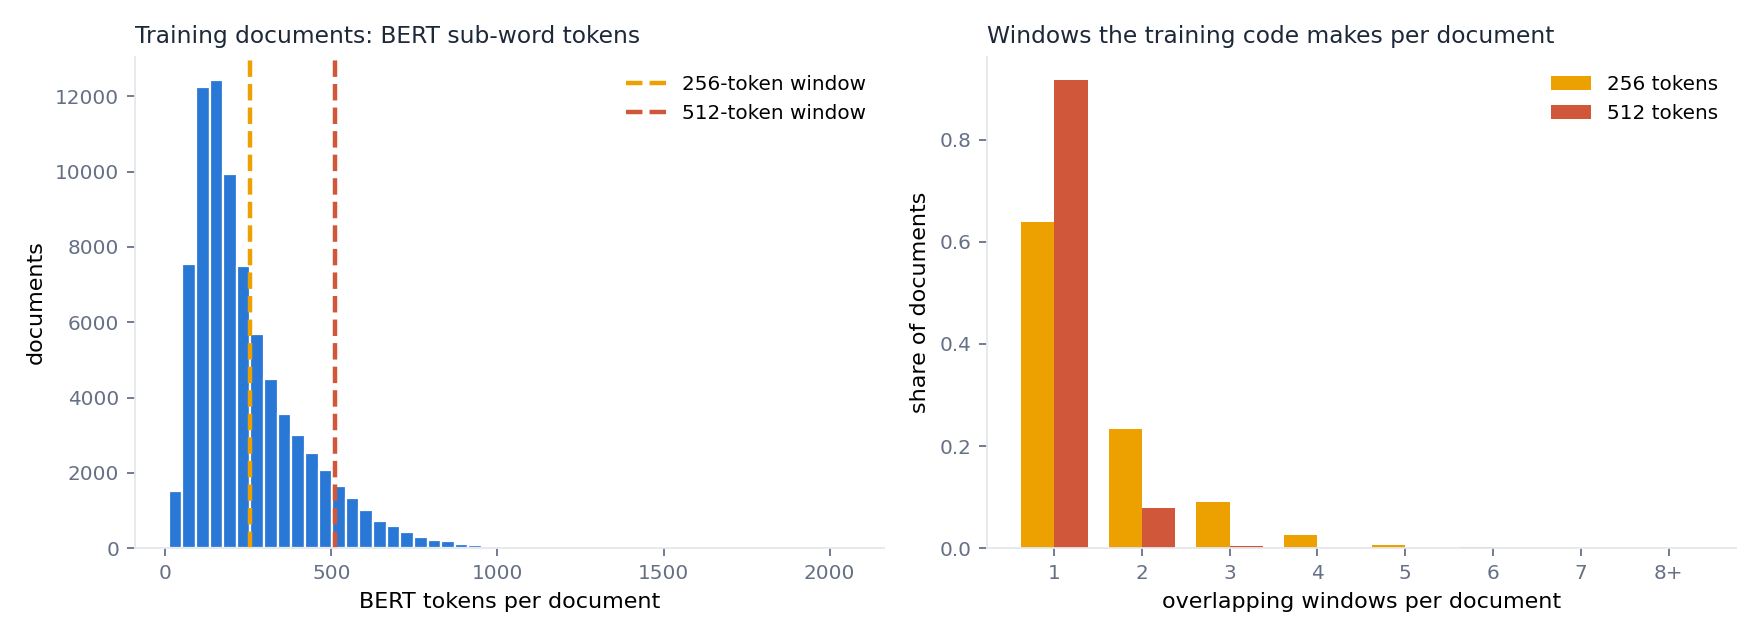

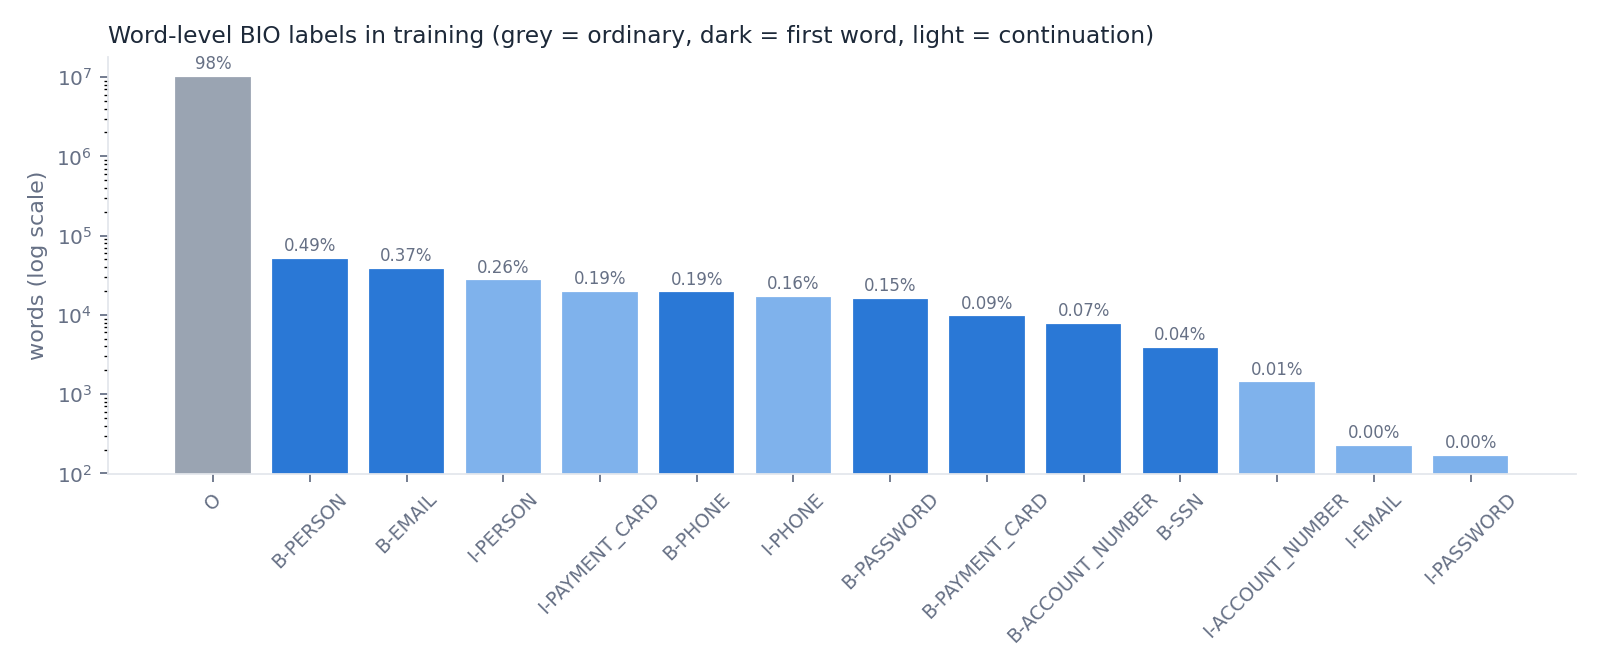

In [ ]:
FEATURES, BIO = di.bert_features(TRAIN, BERT, max_lengths=(256, 512), stride=TRAIN_CFG["stride"])
FEATURE_SUMMARY = di.feature_summary(FEATURES, (256, 512))
display(FEATURE_SUMMARY); display(BIO)
display(Image(di.length_chart(FEATURES, REPORT / "bert_lengths_windows.png")))
display(Image(di.bio_chart(BIO, REPORT / "bio_labels.png")))
FEATURE_SUMMARY.to_csv(REPORT / "bert_feature_summary.csv", index=False); BIO.to_csv(REPORT / "bio_label_counts.csv", index=False)

## 12. Data insights
**Entities per category,** per 1,000 documents in each split: a grouped random split should give the same mix in train, validation and test. **Locale:** Nemotron pairs each US record with an international version, so the two locales are balanced; later notebooks use this to check the model for a locale gap. **Domains:** the spread of subject areas in training (legal, hospitality, cybersecurity and many more), which later notebooks use to find domains where the model leaks more.

split,test,train,validation
category,,,
ACCOUNT_NUMBER,166.9,99.4,104.0
EMAIL,543.5,497.1,498.8
PASSWORD,184.8,207.6,216.4
PAYMENT_CARD,173.4,124.6,131.8
PERSON,971.7,664.5,665.1
PHONE,236.4,249.7,254.3
SSN,61.1,50.1,46.8


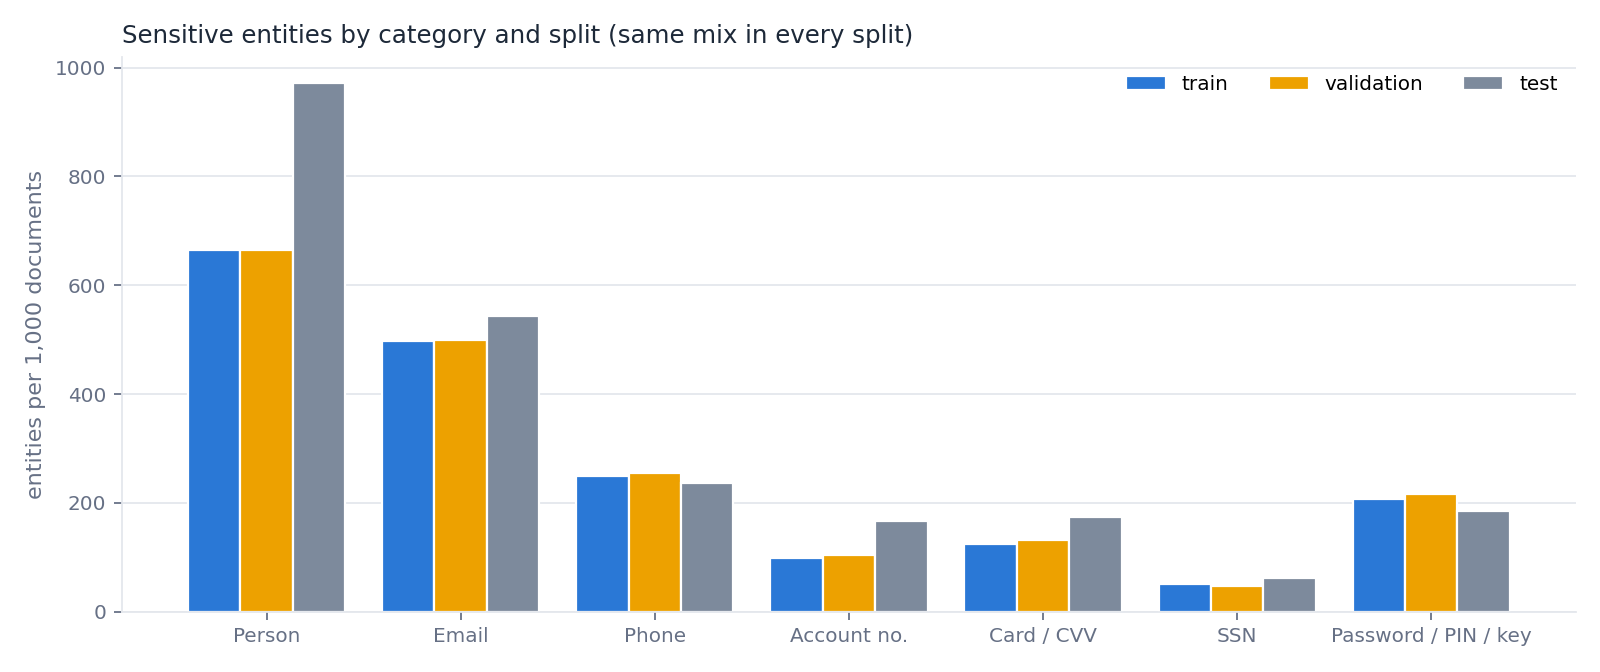

split,test,train,validation
locale,,,
intl,4999,39823,9949
us,5001,39775,9950


30 domains in training


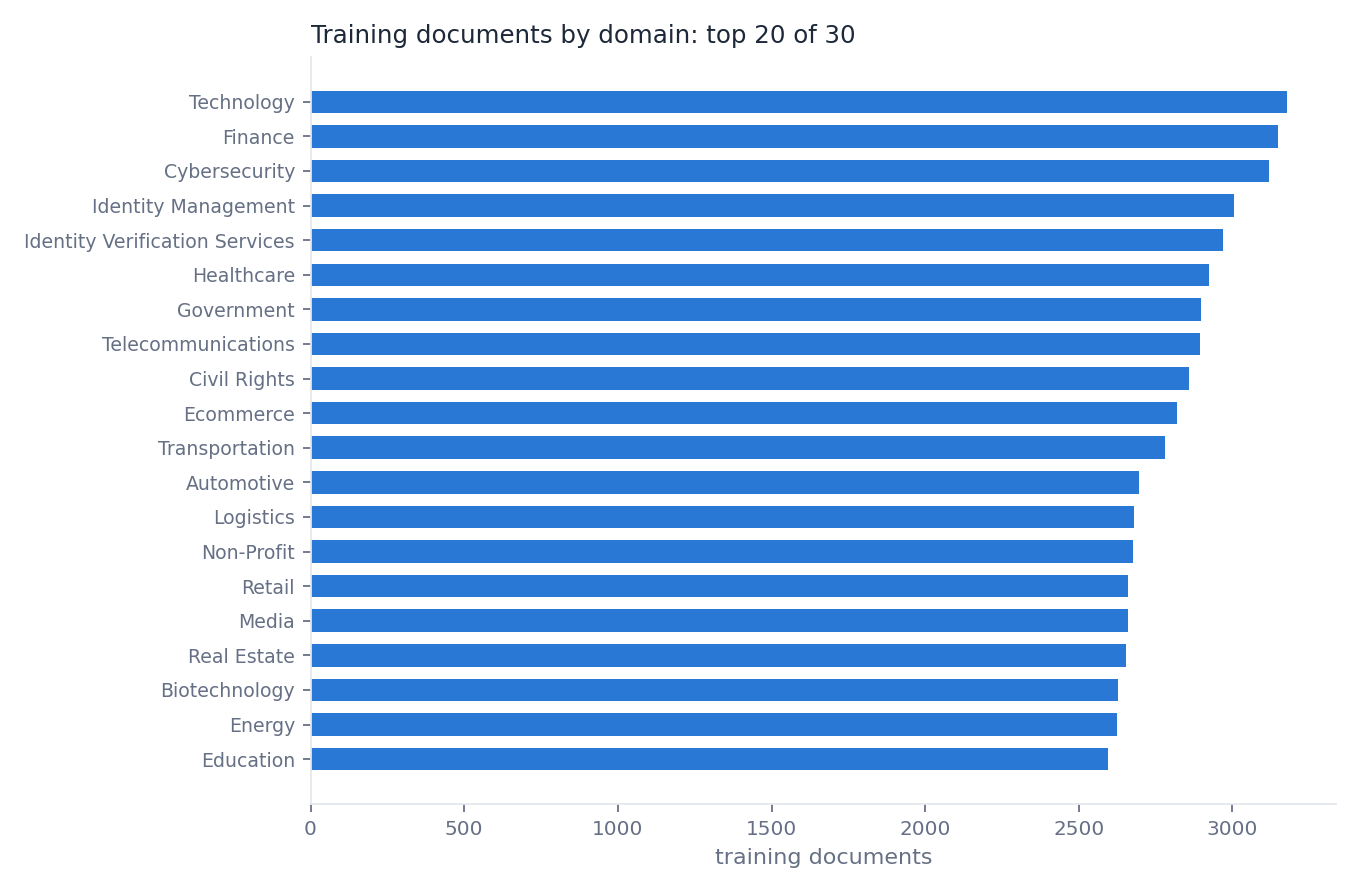

In [ ]:
ENTITIES = di.entity_table(text["audit"])
display(ENTITIES.pivot(index="category", columns="split", values="per_1000_documents"))
display(Image(di.entity_chart(ENTITIES, REPORT / "entities_by_category.png")))
LOCALE, DOMAINS = di.mix_tables(text["audit"])
display(LOCALE.pivot(index="locale", columns="split", values="documents"))
print(DOMAINS[DOMAINS.split == "train"].domain.nunique(), "domains in training")
display(Image(di.domain_chart(DOMAINS, REPORT / "domains.png")))
for t, n in ((ENTITIES, "entities_by_category"), (LOCALE, "locale"), (DOMAINS, "domains")):
    t.to_csv(REPORT / f"{n}.csv", index=False)

## 13. Screenshots: OCR by category and rendering coverage
Section 8's OCR results, broken down by category on the validation screenshots. Passwords, PINs and API keys mix letters, digits, symbols and look-alike characters (l and 1, O and 0), so they are the hardest text for OCR to read exactly; this explains part of the PASSWORD weakness measured later, before the model is even involved. The second chart counts each rendering setting in the training sample, to show the variety is actually present.

format,jpeg,png
category,,
ACCOUNT_NUMBER,0.981,0.991
EMAIL,0.922,0.909
PASSWORD,0.597,0.597
PAYMENT_CARD,0.991,0.983
PERSON,0.977,0.977
PHONE,0.882,0.890
SSN,0.944,0.953


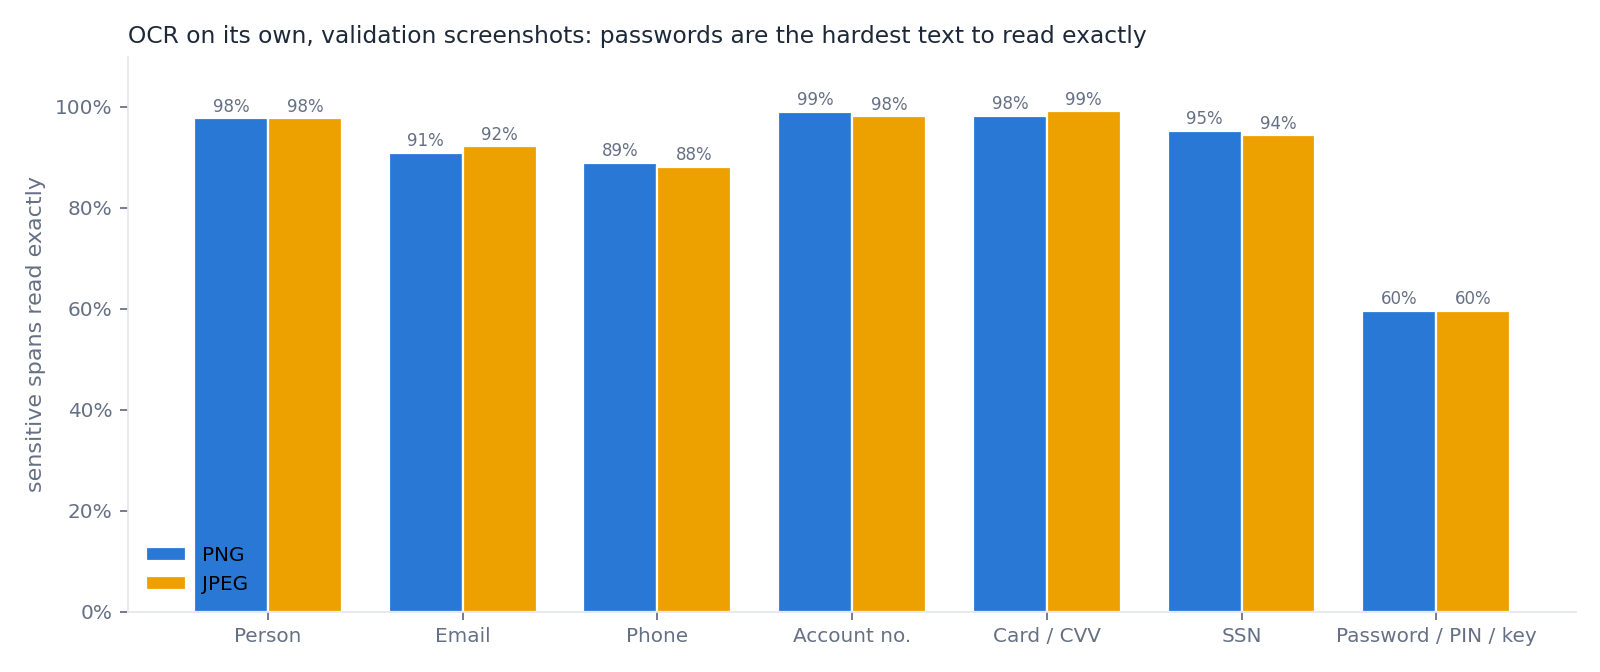

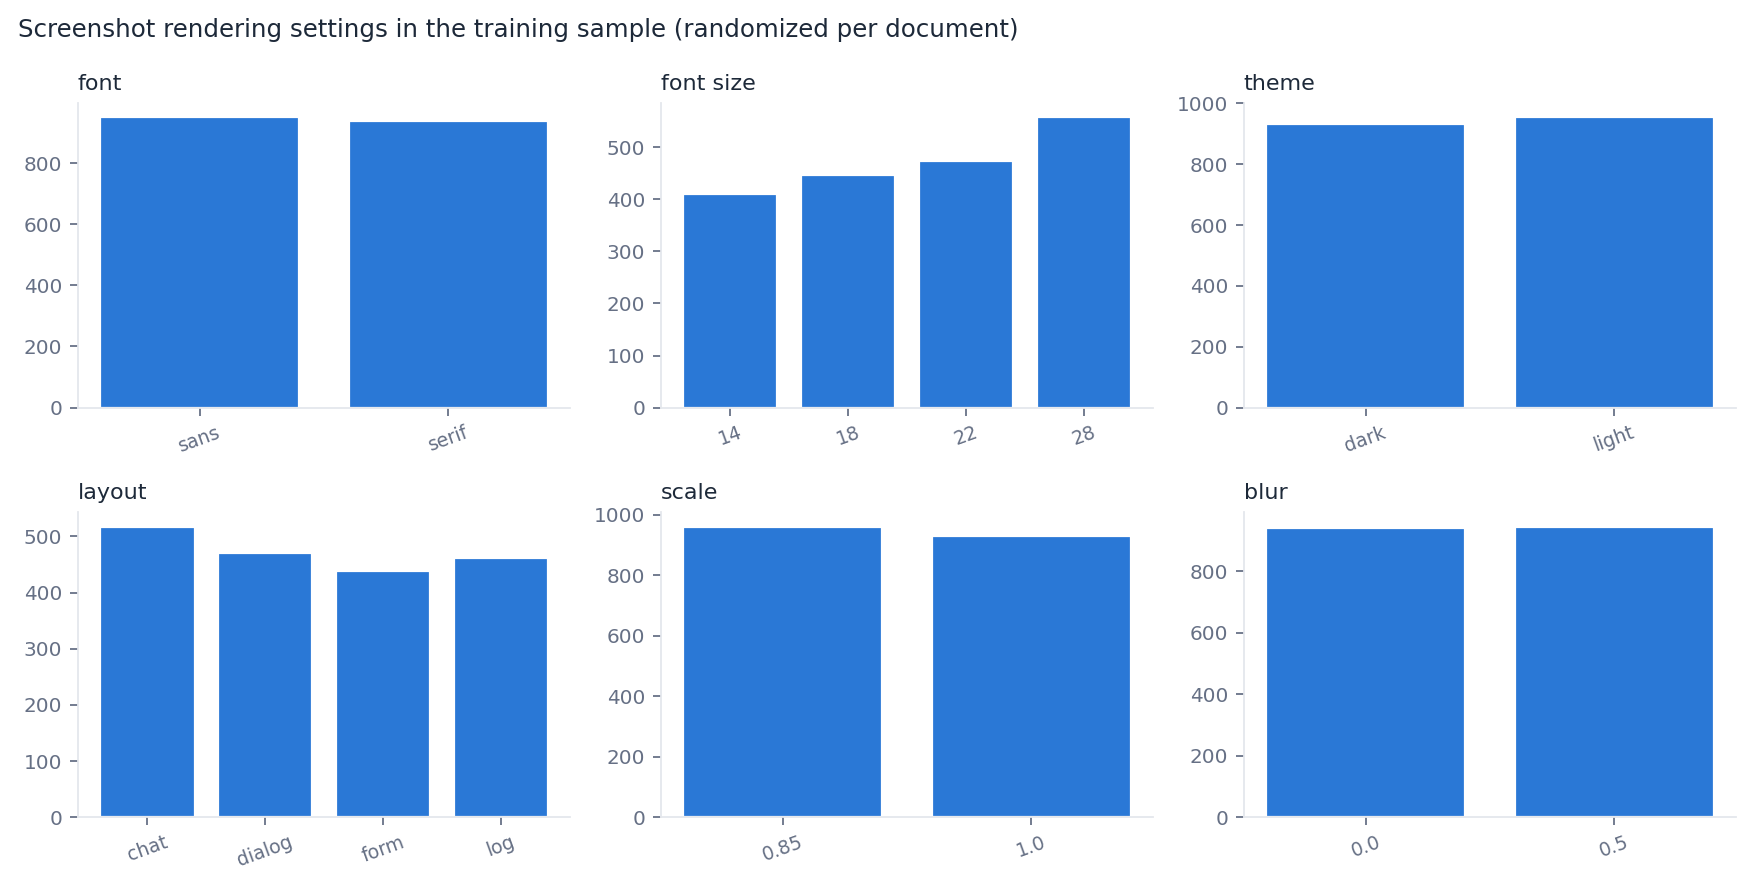

In [ ]:
OCR_CAT = di.ocr_read_by_category(images["summary"])
display(OCR_CAT[OCR_CAT.split == "validation"].pivot(index="category", columns="format", values="read_exact_rate").round(3))
display(Image(di.ocr_category_chart(OCR_CAT, REPORT / "ocr_read_exact_by_category.png")))
RECORDS = [json.loads(l) for s in ("train", "validation")
           for l in (IMAGES / f"records/{s}.jsonl").read_text().splitlines() if l.strip()]
RENDER = di.rendering_table(RECORDS)
display(Image(di.rendering_chart(RENDER, REPORT / "rendering_settings.png")))
OCR_CAT.to_csv(REPORT / "ocr_by_category.csv", index=False); RENDER.to_csv(REPORT / "rendering_settings.csv", index=False)

## 14. Key numbers, and download the charts
Collects the main figures from sections 6 to 13 in one place (also saved as `key_numbers.json`), and downloads every chart and table as `data_prep_report.zip`.

In [ ]:
f = FEATURES
val_ocr = OCR_CAT[(OCR_CAT.split == "validation") & (OCR_CAT.format == "png")].set_index("category")
KEY = {
    "source_rows": int(FUNNEL.rows.iloc[0]), "final_documents": int(FUNNEL.rows.iloc[-1]),
    "removed": {r.step: int(-r.rows) for r in FUNNEL.itertuples() if r.rows < 0},
    "rejection_reasons": dict(zip(REJECTED.reason, REJECTED.rows.astype(int))),
    "splits": SPLITS.set_index("split")[["documents", "groups", "share_without_sensitive_text"]].to_dict("index"),
    "split_overlap_all_zero": bool((LEAKAGE.drop(columns="key") == 0).all().all()),
    "mapped_source_labels": len(config["label_map"]),
    "unmapped_source_labels": int((mapping.mapped_to == "(not mapped)").sum()),
    "bert_tokens_per_doc_median": float(f.tokens.median()),
    "bert_tokens_per_word_mean": round(float((f.tokens / f.words).mean()), 2),
    "docs_needing_2plus_windows_at_256": round(float((f.windows_256 > 1).mean()), 4),
    "docs_needing_2plus_windows_at_512": round(float((f.windows_512 > 1).mean()), 4),
    "share_words_labelled_O": round(float(BIO.set_index("tag").loc["O", "share"]), 4),
    "ocr_overall": {k: round(images["summary"]["overall"][k], 4) for k in ("cer", "wer", "word_recall",
                    "sensitive_located_rate", "sensitive_read_exact_rate")},
    "ocr_read_exact_validation_png": val_ocr.read_exact_rate.round(3).to_dict(),
}
print(json.dumps(KEY, indent=1))
(REPORT / "key_numbers.json").write_text(json.dumps(KEY, indent=1))
for folder in (PREPARED / "figures", IMAGES / "figures"):
    for png in folder.glob("*.png"):
        shutil.copy(png, REPORT / png.name)
shutil.make_archive("/content/data_prep_report", "zip", REPORT)
try:
    from google.colab import files
    files.download("/content/data_prep_report.zip")
except Exception:
    print("Saved /content/data_prep_report.zip")

{
 "source_rows": 200000,
 "final_documents": 109497,
 "removed": {
  "Rejected: invalid records": 759,
  "Removed: training rows in the same group as a test row": 8,
  "Removed: exact duplicates": 1,
  "Official test rows not sampled": 89735
 },
 "rejection_reasons": {
  "in_scope_surface_mismatch": 759
 },
 "splits": {
  "train": {
   "documents": 79598,
   "groups": 39927,
   "share_without_sensitive_text": 0.2443
  },
  "validation": {
   "documents": 19899,
   "groups": 9981,
   "share_without_sensitive_text": 0.2426
  },
  "test": {
   "documents": 10000,
   "groups": 5012,
   "share_without_sensitive_text": 0.1645
  }
 },
 "split_overlap_all_zero": true,
 "mapped_source_labels": 11,
 "unmapped_source_labels": 44,
 "bert_tokens_per_doc_median": 198.0,
 "bert_tokens_per_word_mean": 2.05,
 "docs_needing_2plus_windows_at_256": 0.3614,
 "docs_needing_2plus_windows_at_512": 0.0835,
 "share_words_labelled_O": 0.9796,
 "ocr_overall": {
  "cer": 0.0308,
  "wer": 0.0359,
  "word_recall": 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Save the run
With `UPLOAD = False`, the prepared documents are copied to Google Drive and a local run record (run ID, code version, split sizes and hashes) is downloaded. It is named `local_run_...` so it cannot be mistaken for a published receipt. With `UPLOAD = True` (the default), the raw, prepared and screenshot bundles are uploaded to Google Cloud Storage with manifests, and a receipt is published last.

In [ ]:
from datetime import datetime, timezone
from google.colab import files
from src.gcs_io import sha256_file

test_hashes = {"text_documents": sha256_file(PREPARED / "docs/test.jsonl"),
               "image_records": sha256_file(IMAGES / "records/test.jsonl")}
if (PREPARED / "sft/test.jsonl").exists():                 # only in legacy chat mode
    test_hashes["text_examples"] = sha256_file(PREPARED / "sft/test.jsonl")

if not UPLOAD:
    print("Not uploaded: UPLOAD is False. The frozen data run is", FROZEN_RUN)
    from google.colab import drive
    drive.mount("/content/drive")
    dest = Path("/content/drive/MyDrive/safeshare_data") / RUN_ID
    shutil.copytree(PREPARED, dest / "prepared", dirs_exist_ok=True)   # add RAW and IMAGES too if you want them
    record = {"run_id": RUN_ID, "published": False, "note": "Local run, not uploaded; not a GCS receipt.",
              "created_utc": datetime.now(timezone.utc).isoformat(), "source_commit": COMMIT,
              "split_summary": text["split_summary"], "test_hashes": test_hashes,
              "manifests": {"prepared": sha256_file(PREPARED / "manifest.json"),
                            "images": sha256_file(IMAGES / "manifest.json")}}
    name = f"local_run_{RUN_ID}.json"
    Path(name).write_text(json.dumps(record, indent=2))
    shutil.copy(name, dest / name)
    print("Copied to", dest)
    files.download(name)
else:
    from src.gcs_io import upload_bundle, write_receipt, find_latest_receipt
    uploads = {kind: upload_bundle(path, f"{DATA_URI}/{kind}/{RUN_ID}", PROJECT, BUCKET, gcs)
               for kind, path in (("raw", RAW), ("prepared", PREPARED), ("images", IMAGES))}
    write_receipt({
        "run_id": RUN_ID, "created_utc": datetime.now(timezone.utc).isoformat(), "source_commit": COMMIT, **uploads,
        "split_summary": text["split_summary"], "label_mapping": label_mapping,
        "image_summary": {k: v for k, v in images["summary"].items() if k != "selected_ids"},
        "test_hashes": test_hashes,
    }, DATA_URI, PROJECT, BUCKET, gcs)
    receipt = find_latest_receipt(DATA_URI, PROJECT, RUN_ID, BUCKET, gcs)
    Path(f"receipt_{RUN_ID}.json").write_text(json.dumps(receipt, indent=2))
    files.download(f"receipt_{RUN_ID}.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary

**Data cleanup.** A pinned version of Nemotron-PII (100,000 train and 100,000 test records) was validated record by record; records with any invalid annotation were removed whole, duplicates and conflicting duplicates were removed, and records were grouped so near-copies stay in one split. The result is 79,598 training documents (39,927 groups), 19,899 validation documents (9,981 groups) and 10,000 test documents (5,012 groups), with zero overlap between splits. The test split was frozen by hash before any model was tuned, and section 10 checks that this notebook rebuilds it.

**Feature engineering.** Eleven source labels map to seven categories; all others stay as ordinary text. Labels are aligned to whole words, then to BERT sub-word tokens with only the first piece of each word labeled, and long documents are cut into overlapping 256-token windows. A balanced sample of 2,000 documents was rendered as about 5,000 PNG and JPEG screenshots with randomized fonts, sizes, themes, layouts, scaling and blur, with gold boxes for every sensitive word.

**Data insights.** Every split has the same mix of categories and a balanced US and international locale. Tesseract alone reaches a character error rate of about 3%, finds about 97% of words and locates 99.96% of sensitive spans, but reads only about 92% of them exactly; passwords are the weak point (about 60% read exactly on validation screenshots, against 89% to 99% for other categories). OCR therefore limits what the detector can catch, and it is evaluated separately throughout the project.

*Figures quoted here are from the frozen run (`20261111T013302Z-e38b2785`); section 14 prints the same figures for this run.*
